In [5]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
ahsan81_hotel_reservations_classification_dataset_path = kagglehub.dataset_download('ahsan81/hotel-reservations-classification-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'hotel-reservations-classification-dataset' dataset.
Data source import complete.


# Import required libraries for data manipulation and analysis


In [6]:
import pandas as pd
import numpy as np
import random
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder


# Load the dataset into a pandas DataFrame




# shape-Display the number of rows and columns in the dataset

In [7]:
import os

# Construct the path to the dataset using the location downloaded by kagglehub
csv_path = os.path.join(ahsan81_hotel_reservations_classification_dataset_path, "Hotel Reservations.csv")

df = pd.read_csv(csv_path)
df.shape

(36275, 19)

# Display the first 5 rows to understand the structure of the data


In [8]:
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


# Get general information about the dataset such as data types and missing values


In [9]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

# Generate descriptive statistics for numerical columns


In [10]:
df.describe()


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests
count,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000
mean,1.844962,0.105279,0.810724,2.204300,0.030986,85.232557,2017.820427,7.423653,15.596995,0.025637,0.023349,0.153411,103.423539,0.619655
std,0.518715,0.402648,0.870644,1.410905,0.173281,85.930817,0.383836,3.069894,8.740447,0.158053,0.368331,1.754171,35.089424,0.786236
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2017.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2018.000000,5.000000,8.000000,0.000000,0.000000,0.000000,80.300000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,57.000000,2018.000000,8.000000,16.000000,0.000000,0.000000,0.000000,99.450000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2018.000000,10.000000,23.000000,0.000000,0.000000,0.000000,120.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,443.000000,2018.000000,12.000000,31.000000,1.000000,13.000000,58.000000,540.000000,5.000000


# Count duplicated rows in the dataset


In [11]:
df.duplicated().sum()


np.int64(0)

 No duplicated rows were found in the dataset


# Check dataset size after cleaning


In [12]:
df.shape

(36275, 19)

# Rename selected columns to make them clearer and more meaningful


In [13]:
df = df.rename(columns={
    'Booking_ID': 'booking_id',
    'no_of_adults': 'num_adults',
    'no_of_children': 'num_children',
    'no_of_weekend_nights': 'weekend_nights',
    'no_of_week_nights': 'weekday_nights',
    'type_of_meal_plan': 'meal_plan',
    'required_car_parking_space': 'parking_required',
    'room_type_reserved': 'room_type',
    'lead_time': 'lead_time_days',
    'arrival_date': 'arrival_day',
    'market_segment_type': 'market_segment',
    'repeated_guest': 'is_repeat_guest',
    'no_of_previous_cancellations': 'previous_cancellations',
    'no_of_previous_bookings_not_canceled': 'previous_non_canceled_bookings',
    'avg_price_per_room': 'average_room_price',
    'no_of_special_requests': 'special_requests_count',
})


Handeling Missing Values

In [14]:
print(df.columns)

Index(['booking_id', 'num_adults', 'num_children', 'weekend_nights',
       'weekday_nights', 'meal_plan', 'parking_required', 'room_type',
       'lead_time_days', 'arrival_year', 'arrival_month', 'arrival_day',
       'market_segment', 'is_repeat_guest', 'previous_cancellations',
       'previous_non_canceled_bookings', 'average_room_price',
       'special_requests_count', 'booking_status'],
      dtype='object')


In [15]:
missing_values = df.isnull().sum()

print(missing_values)

booking_id                        0
num_adults                        0
num_children                      0
weekend_nights                    0
weekday_nights                    0
meal_plan                         0
parking_required                  0
room_type                         0
lead_time_days                    0
arrival_year                      0
arrival_month                     0
arrival_day                       0
market_segment                    0
is_repeat_guest                   0
previous_cancellations            0
previous_non_canceled_bookings    0
average_room_price                0
special_requests_count            0
booking_status                    0
dtype: int64


Data Sampling

In [16]:
random.seed(42)

In [17]:
unique_meals = df['meal_plan'].unique()
random_meals = random.sample(list(unique_meals), 2)
print(random_meals)


['Meal Plan 1', 'Meal Plan 3']


In [18]:
hotel_sample = df[df['meal_plan'].isin(random_meals)]

In [19]:
print("Total number of rows in the new sample:", len(hotel_sample))
print("-" * 35)
print("Meal types included in the sample:")
print(hotel_sample['meal_plan'].value_counts())

Total number of rows in the new sample: 27840
-----------------------------------
Meal types included in the sample:
meal_plan
Meal Plan 1    27835
Meal Plan 3        5
Name: count, dtype: int64


Data Summarization

In [20]:
hotel_count = hotel_sample['meal_plan'].value_counts()

print(hotel_count)


meal_plan
Meal Plan 1    27835
Meal Plan 3        5
Name: count, dtype: int64


In [21]:
meal_pivot = pd.pivot_table(
    data=df,
    index='meal_plan',
    values='booking_id',
    aggfunc='nunique'
).reset_index()

meal_pivot.columns = ['meal_plan', 'booking_count']
print(meal_pivot)


      meal_plan  booking_count
0   Meal Plan 1          27835
1   Meal Plan 2           3305
2   Meal Plan 3              5
3  Not Selected           5130


In [22]:
num_bookings = df['booking_id'].nunique()
print("Number of unique bookings:", num_bookings)

num_meal_plans = df['meal_plan'].nunique()
print("Number of unique meal plans:", num_meal_plans)


Number of unique bookings: 36275
Number of unique meal plans: 4


In [23]:
meal_plan_groupby = (
    df.groupby('meal_plan')['booking_id']
    .nunique()
    .reset_index(name='booking_count')
)

print("Number of bookings per meal plan:")
print(meal_plan_groupby)


Number of bookings per meal plan:
      meal_plan  booking_count
0   Meal Plan 1          27835
1   Meal Plan 2           3305
2   Meal Plan 3              5
3  Not Selected           5130


Visualization

/tmp/ipykernel_615/4142033338.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


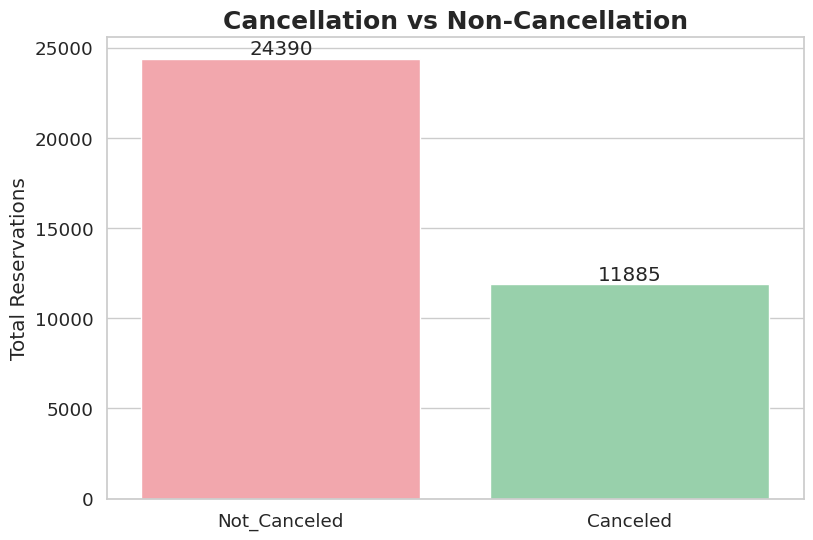

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", font_scale=1.2)

plt.figure(figsize=(9,6))

ax = sns.countplot(
    data=df,
    x='booking_status',
    palette=['#FF9AA2', '#8FD9A8']
)

plt.title("Cancellation vs Non-Cancellation", fontsize=18, weight='bold')
plt.xlabel("")
plt.ylabel("Total Reservations")


for container in ax.containers:
    ax.bar_label(container)

plt.show()


The visualization illustrates the relationship between the average room price and booking cancellation status

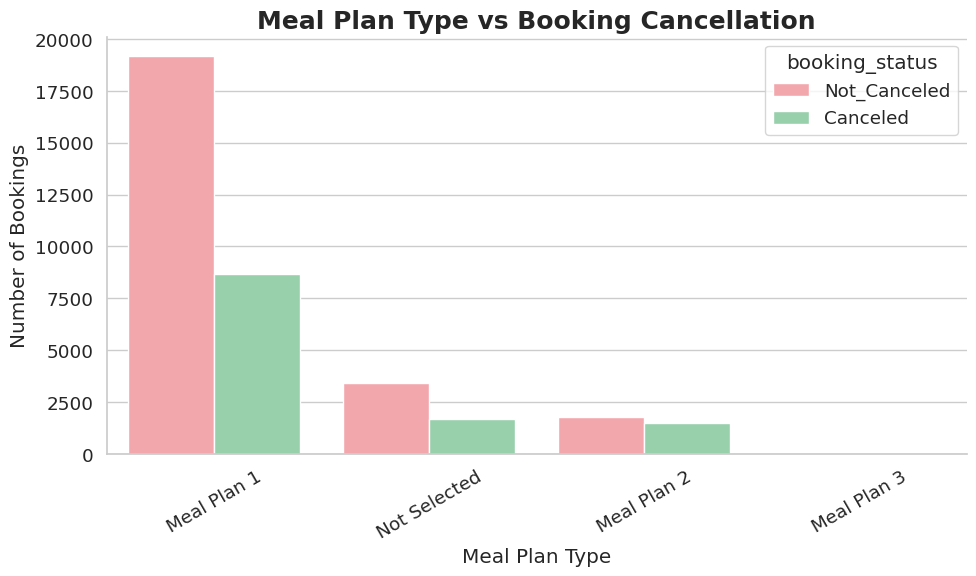

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", font_scale=1.2)

plt.figure(figsize=(10,6))

ax = sns.countplot(
    data=df,
    x='meal_plan',
    hue='booking_status',
    palette=['#FF9AA2', '#8FD9A8']
)

plt.title(
    "Meal Plan Type vs Booking Cancellation",
    fontsize=18,
    weight='bold'
)

plt.xlabel("Meal Plan Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=30)
sns.despine()
plt.tight_layout()

plt.show()


This chart compares meal plans with booking cancellations. We can see that some meal plans have more cancellations than others.

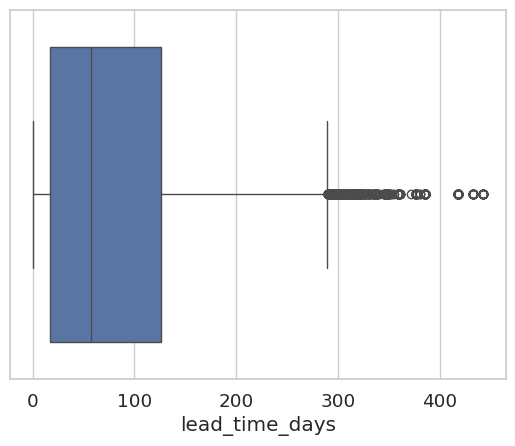

In [26]:
sns.boxplot(x=df['lead_time_days'])
plt.show()

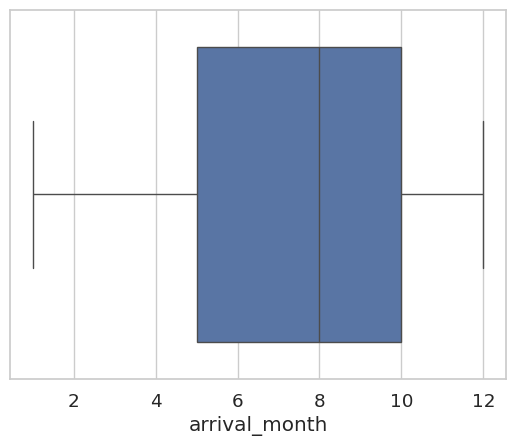

In [27]:
sns.boxplot(x=df['arrival_month'])
plt.show()

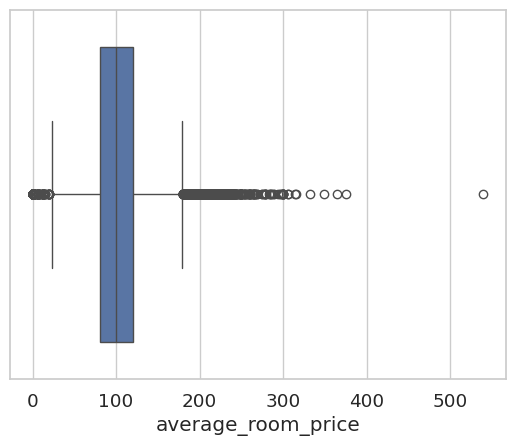

In [28]:
sns.boxplot(x=df['average_room_price'])
plt.show()

In [29]:
Q1 = df['average_room_price'].quantile(0.25)
Q3 = df['average_room_price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 80.3
Q3: 120.0
IQR: 39.7
Lower Bound: 20.749999999999993
Upper Bound: 179.55


In [30]:
outliers = df[
    (df['average_room_price'] < lower_bound) |
    (df['average_room_price'] > upper_bound)
]

print("Number of outliers:", len(outliers))

print(outliers[['booking_id','average_room_price']].head())

Number of outliers: 1696
    booking_id  average_room_price
60    INN00061              258.00
63    INN00064                0.00
114   INN00115              184.24
127   INN00128              190.80
145   INN00146                0.00


In [31]:
outliers.sort_values(by='average_room_price').head()

outliers.sort_values(by='average_room_price', ascending=False).head()

,booking_id,num_adults,num_children,weekend_nights,weekday_nights,meal_plan,parking_required,room_type,lead_time_days,arrival_year,arrival_month,arrival_day,market_segment,is_repeat_guest,previous_cancellations,previous_non_canceled_bookings,average_room_price,special_requests_count,booking_status
33114,INN33115,2,0,0,1,Meal Plan 1,0,Room_Type 1,35,2018,3,25,Offline,0,0,0,540.00,0,Canceled
9461,INN09462,3,0,0,2,Meal Plan 1,0,Room_Type 4,21,2018,12,30,Online,0,0,0,375.50,0,Not_Canceled
20900,INN20901,2,1,1,2,Meal Plan 2,0,Room_Type 1,173,2018,7,25,Offline,0,0,0,365.00,1,Canceled
34306,INN34307,2,2,0,3,Meal Plan 2,0,Room_Type 6,43,2018,12,29,Online,0,0,0,349.63,1,Not_Canceled
14773,INN14774,2,2,0,3,Meal Plan 1,0,Room_Type 6,28,2018,6,2,Online,0,0,0,332.57,1,Not_Canceled


In [32]:
df_clean = df[
    (df['average_room_price'] >= lower_bound) &
    (df['average_room_price'] <= upper_bound)
]

print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

Original dataset shape: (36275, 19)
Clean dataset shape: (34579, 19)


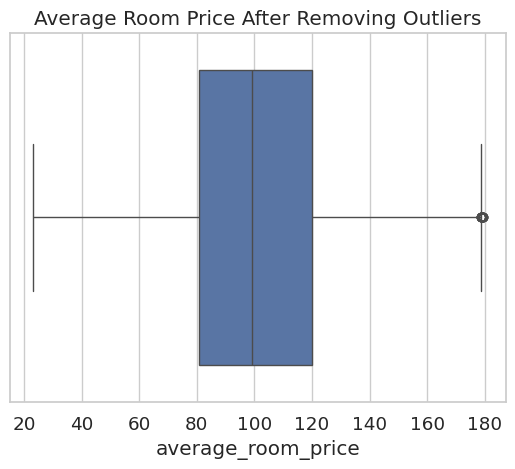

In [33]:
sns.boxplot(x=df_clean['average_room_price'])
plt.title("Average Room Price After Removing Outliers")
plt.show()

In [34]:
Q1 = df['arrival_month'].quantile(0.25)
Q3 = df['arrival_month'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 5.0
Q3: 10.0
IQR: 5.0
Lower Bound: -2.5
Upper Bound: 17.5


In [35]:
outliers = df[
    (df['arrival_month'] < lower_bound) |
    (df['arrival_month'] > upper_bound)
]

print("Number of outliers:", len(outliers))

print(outliers[['booking_id','arrival_month']].head())

Number of outliers: 0
Empty DataFrame
Columns: [booking_id, arrival_month]
Index: []


In [36]:
outliers.sort_values(by='arrival_month').head()

outliers.sort_values(by='arrival_month', ascending=False).head()

,booking_id,num_adults,num_children,weekend_nights,weekday_nights,meal_plan,parking_required,room_type,lead_time_days,arrival_year,arrival_month,arrival_day,market_segment,is_repeat_guest,previous_cancellations,previous_non_canceled_bookings,average_room_price,special_requests_count,booking_status


In [37]:
df_clean = df[
    (df['arrival_month'] >= lower_bound) &
    (df['arrival_month'] <= upper_bound)
]

print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

Original dataset shape: (36275, 19)
Clean dataset shape: (36275, 19)


In [38]:
pd.get_dummies(df['booking_status'])

,Canceled,Not_Canceled
0,False,True
1,False,True
2,True,False
3,True,False
4,True,False
...,...,...
36270,False,True
36271,True,False
36272,False,True
36273,True,False


one hote

In [39]:
pd.get_dummies(df['meal_plan'])

,Meal Plan 1,Meal Plan 2,Meal Plan 3,Not Selected
0,True,False,False,False
1,False,False,False,True
2,True,False,False,False
3,True,False,False,False
4,False,False,False,True
...,...,...,...,...
36270,True,False,False,False
36271,True,False,False,False
36272,True,False,False,False
36273,False,False,False,True


one hot encoding

In [40]:
pd.get_dummies(df['market_segment'])

,Aviation,Complementary,Corporate,Offline,Online
0,False,False,False,True,False
1,False,False,False,False,True
2,False,False,False,False,True
3,False,False,False,False,True
4,False,False,False,False,True
...,...,...,...,...,...
36270,False,False,False,False,True
36271,False,False,False,False,True
36272,False,False,False,False,True
36273,False,False,False,False,True


one hote

In [41]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['room_type'] = le.fit_transform(df['room_type'])

print(df[['room_type']].head())

   room_type
0          0
1          0
2          0
3          0
4          0


lable

In [42]:
target_columns = [
    'meal_plan',
    'market_segment',
    'booking_status',
    'room_type'
]

# Scaling
le = LabelEncoder()
for col in target_columns:
    df[col] = le.fit_transform(df[col].astype(str))

#  MinMaxScaler
mms = MinMaxScaler()
df_minmax = df.copy()
df_minmax[target_columns] = mms.fit_transform(df[target_columns])

# StandardScaler
std_scaler = StandardScaler()
df_standard = df.copy()
df_standard[target_columns] = std_scaler.fit_transform(df[target_columns])


print("--- MinMaxScaler ---")
print(df_minmax[target_columns].head())

print("\n--- StandardScaler ---")
print(df_standard[target_columns].head())


--- MinMaxScaler ---
   meal_plan  market_segment  booking_status  room_type
0        0.0            0.75             1.0        0.0
1        1.0            1.00             1.0        0.0
2        0.0            1.00             0.0        0.0
3        0.0            1.00             0.0        0.0
4        1.0            1.00             0.0        0.0

--- StandardScaler ---
   meal_plan  market_segment  booking_status  room_type
0  -0.491972       -0.810601        0.698062  -0.506411
1   2.370304        0.656692        0.698062  -0.506411
2  -0.491972        0.656692       -1.432539  -0.506411
3  -0.491972        0.656692       -1.432539  -0.506411
4   2.370304        0.656692       -1.432539  -0.506411


In [43]:
df = df.drop('booking_id', axis=1)

We removed booking_id because it creates misleading correlations and does not represent meaningful information.

In [44]:
X = df.drop('booking_status', axis=1)
y = df['booking_status']


X = X.drop([
    'arrival_day',
    'arrival_month',
    'room_type',
    'meal_plan',
    'num_children'
], axis=1)

Then we used correlation to analyze and remove weak features. After that, we split the data into training and testing sets to evaluate the model properly.

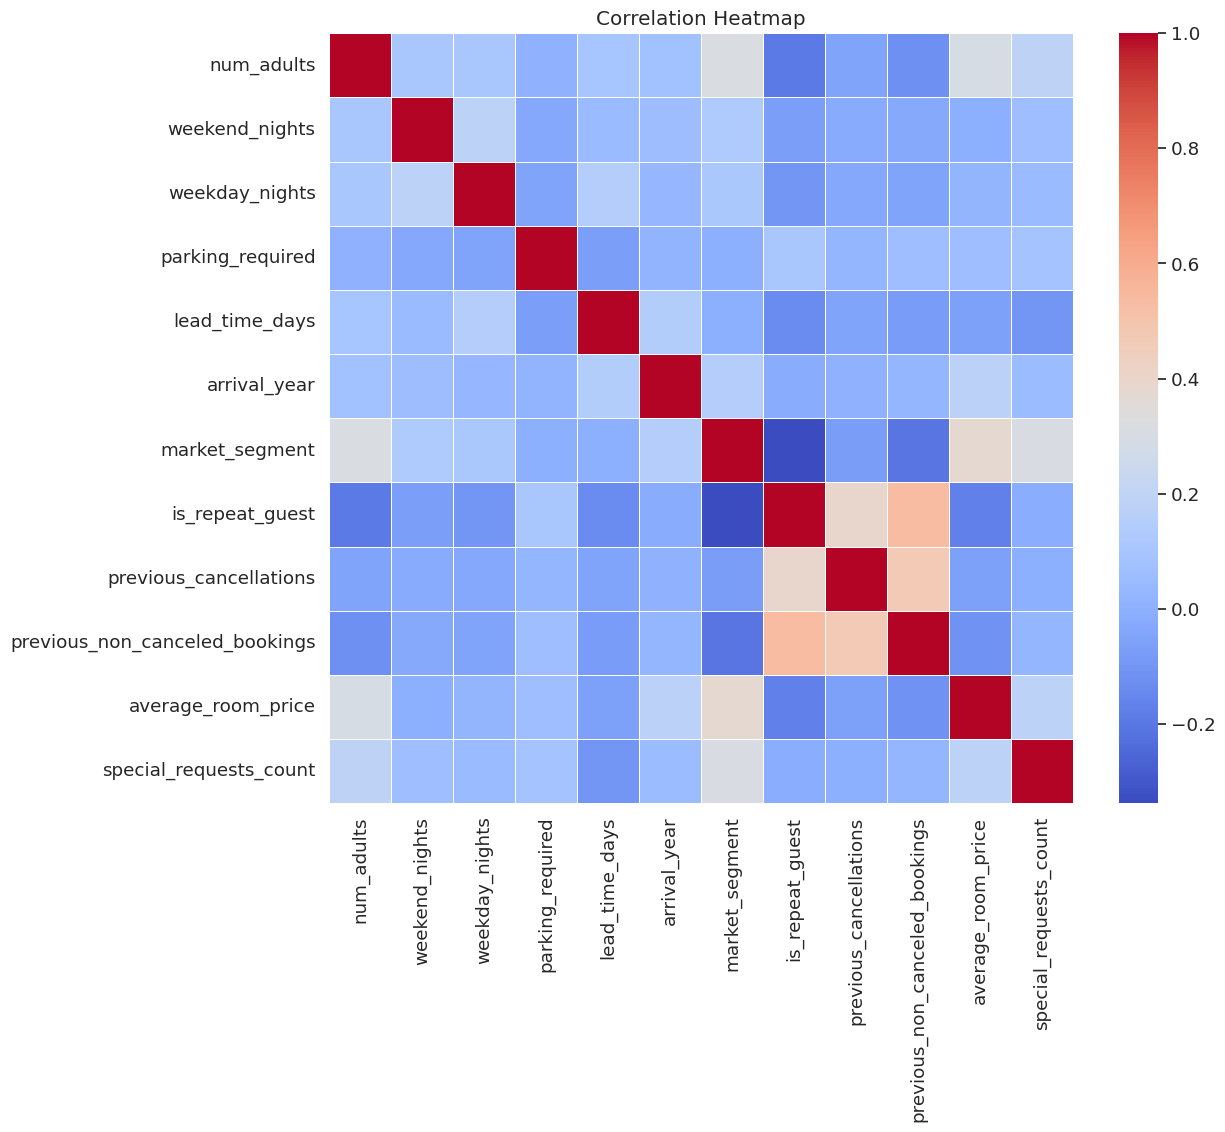

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

# نحسب correlation على X فقط (مو df)
corr = X.corr()

plt.figure(figsize=(12, 10))  # كبرنا الحجم عشان يوضح

sns.heatmap(
    corr,
    cmap='coolwarm',
    annot=False,      # ❌ شيلي الأرقام عشان ما تتداخل
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

We computed the correlation matrix for the features only to identify highly correlated features and avoid redundancy. The target variable (booking_status) was excluded because this step focuses on relationships between features, not with the target.

In [46]:
corr_with_target = X.corrwith(y).sort_values(ascending=False)
print(corr_with_target)

special_requests_count            0.253070
is_repeat_guest                   0.107287
parking_required                  0.086185
previous_non_canceled_bookings    0.060179
previous_cancellations            0.033728
weekend_nights                   -0.061563
num_adults                       -0.086920
weekday_nights                   -0.092996
market_segment                   -0.136008
average_room_price               -0.142569
arrival_year                     -0.179529
lead_time_days                   -0.438538
dtype: float64


We calculated the correlation between each feature and the target variable to identify the most important features and remove weak ones before applying RFE.

In [47]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

model = LinearRegression()

rfe = RFE(model, n_features_to_select=5)  # اختاري 5 اهم فيتشرز

X_selected = rfe.fit_transform(X, y)

selected_features = X.columns[rfe.support_]
print(selected_features)

Index(['parking_required', 'arrival_year', 'market_segment', 'is_repeat_guest',
       'special_requests_count'],
      dtype='object')


We applied RFE using Linear Regression to select the most important features based on model performance. The model iteratively removed less important features until only the top 5 features remained.

In [48]:
from sklearn.preprocessing import StandardScaler

# نستخدم فقط الأعمدة الرقمية
X = X.select_dtypes(include=['int64', 'float64'])

# Scaling (مهم جداً قبل PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Data Preparation
Only numerical features were selected since PCA works with numeric data.
StandardScaler was applied to scale the features, as PCA is sensitive to differences in feature values.


In [49]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

PCA was used to reduce the dataset to 2 components (PC1 and PC2) after scaling the data. It simplifies the data while keeping the most important information for analysis and visualization. The result is used for easier interpretation and plotting.

In [50]:
print("Explained Variance Ratio:", pca.explained_variance_ratio_)

Explained Variance Ratio: [0.20117042 0.13578993]


Explained Variance Ratio

This shows how much variance (information) is captured by each principal component. It helps us understand how much data is preserved after applying PCA.

In [51]:
pca_df=pd.DataFrame(X_pca, columns=["PCA1", "PCA2"])
print(pca_df.head())

       PCA1      PCA2
0  0.696393 -1.754505
1 -0.870253  0.770560
2  0.661130 -0.797365
3 -0.416298 -0.456448
4 -0.203121 -0.120800


In [52]:
pca_components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=['PC1', 'PC2']
)

print(pca_components)

     num_adults  weekend_nights  weekday_nights  parking_required  \
PC1   -0.332341       -0.134322       -0.157548          0.046793   
PC2    0.274921        0.090719        0.030146          0.220409   

     lead_time_days  arrival_year  market_segment  is_repeat_guest  \
PC1       -0.108062     -0.127888       -0.427178         0.469159   
PC2       -0.161790      0.227862        0.299849         0.288616   

     previous_cancellations  previous_non_canceled_bookings  \
PC1                0.324289                        0.413067   
PC2                0.397645                        0.394326   

     average_room_price  special_requests_count  
PC1           -0.324158               -0.181674  
PC2            0.345036                0.427469  


lab 7

تحميل المكتبات من السلايدات

In [53]:
!pip install nltk wordcloud --quiet

# ===== استدعاء المكتبات =====
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from collections import Counter

# ===== تحميل بيانات NLTK (الحل الأساسي للمشكلة) =====
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

print("✅ تم استدعاء جميع المكتبات بنجاح")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


✅ تم استدعاء جميع المكتبات بنجاح


## Setup
We install and import required NLP libraries and download necessary NLTK resources for text processing.

In [55]:
import kagglehub
import os

# Download the hotel-reviews dataset from Kaggle
hotel_reviews_path = kagglehub.dataset_download('juhibhojani/hotel-reviews')

# Construct the absolute path to the CSV file
csv_filepath = os.path.join(hotel_reviews_path, 'hotel_reviews.csv')

# Load the dataset into pandas
data_Yelp = pd.read_csv(csv_filepath)

100%|██████████| 319k/319k [00:00<00:00, 500kB/s]

Extracting files...


In [56]:
data_Yelp.head()

,Index,Name,Area,Review_Date,Rating_attribute,Rating(Out of 10),Review_Text
0,0,Hotel The Pearl,"Paharganj, New Delhi",Jul-23,Best budget friendly hotel,9.0,Hotel the pearl is perfect place to stay in De...
1,1,Hotel The Pearl,"Paharganj, New Delhi",Aug-23,Amazing place,9.0,Location of the hotel is perfect. The hotel is...
2,2,Hotel The Pearl,"Paharganj, New Delhi",Aug-23,Overall good stay. Economic.,9.0,"Location, Indian food."
3,3,Hotel The Pearl,"Paharganj, New Delhi",Aug-23,Lovely,9.0,The location and the hotel itself is great. Ne...
4,4,Hotel The Pearl,"Paharganj, New Delhi",Aug-23,Great hotel Great staff and great staying,9.0,Friendly and smiling staffs.. The reception st...


In [57]:
sample_dh = data_Yelp.sample(n=5, random_state=42)

## Data Loading
We load the dataset and take a small random sample for easier analysis.

In [58]:
sample_dh['cleaned_text'] = sample_dh['Review_Text'].str.lower()
sample_dh['Review_Text'] = sample_dh['Review_Text'].str.replace(r'[^\w\s]', '', regex=True)
print(sample_dh[['Review_Text', 'cleaned_text']].head())

                                            Review_Text  \
5760  The room is comfortable and the staff is frien...   
2944           Manager Ashish was very helpful and nice   
2024  was so clean and the room service was free and...   
263   Wonderful ambience very polite staff\nBreakfas...   
4421                       Nice location and nice rooms   

                                           cleaned_text  
5760  the room is comfortable and the staff is frien...  
2944           manager ashish was very helpful and nice  
2024  was so clean and the room service was free and...  
263   wonderful ambience, very polite staff\nbreakfa...  
4421                       nice location and nice rooms  


## Cleaning
We convert text to lowercase and remove punctuation to standardize the data.

In [59]:
# قائمة يدوية بالكلمات الشائعة
stops = ['the', 'is', 'and', 'to', 'in', 'it', 'of', 'i', 'for', 'with', 'on', 'at', 'this', 'that']

# تنظيف عمود Review_Text
sample_dh['Review_Text'] = sample_dh['Review_Text'].apply(lambda x: " ".join([word for word in str(x).split() if word not in stops]))


## Stopwords Removal
We remove common words that do not add meaning to focus on important terms.

In [60]:

# طباعة النتيجة للتأكد
print(sample_dh['Review_Text'].head())

5760    The room comfortable staff friendly attentive ...
2944                 Manager Ashish was very helpful nice
2024    was so clean room service was free price was a...
263     Wonderful ambience very polite staff Breakfast...
4421                             Nice location nice rooms
Name: Review_Text, dtype: object


## Summary
The text is now cleaned and ready for further NLP processing.

In [61]:
sample = data_Yelp['Review_Text'].head(1)

tokens = word_tokenize(sample.iloc[0])

print("Original:", sample.iloc[0])
print("Tokens:", tokens)

Original: Hotel the pearl is perfect place to stay in Delhi Paharganj. whole staff are very helpful, informative. Rooms are clean and comfortable. The hotel's location was very convenient, and we had a truly wonderful stay.. Most recommended..
Tokens: ['Hotel', 'the', 'pearl', 'is', 'perfect', 'place', 'to', 'stay', 'in', 'Delhi', 'Paharganj', '.', 'whole', 'staff', 'are', 'very', 'helpful', ',', 'informative', '.', 'Rooms', 'are', 'clean', 'and', 'comfortable', '.', 'The', 'hotel', "'s", 'location', 'was', 'very', 'convenient', ',', 'and', 'we', 'had', 'a', 'truly', 'wonderful', 'stay', '..', 'Most', 'recommended', '..']


## Tokenization
We split the text into individual words (tokens) to make it easier for processing.

In [62]:

stemmer = PorterStemmer()

stemmed = [stemmer.stem(word) for word in tokens]

print("Stemmed:", stemmed)

Stemmed: ['hotel', 'the', 'pearl', 'is', 'perfect', 'place', 'to', 'stay', 'in', 'delhi', 'paharganj', '.', 'whole', 'staff', 'are', 'veri', 'help', ',', 'inform', '.', 'room', 'are', 'clean', 'and', 'comfort', '.', 'the', 'hotel', "'s", 'locat', 'wa', 'veri', 'conveni', ',', 'and', 'we', 'had', 'a', 'truli', 'wonder', 'stay', '..', 'most', 'recommend', '..']


## Stemming
We reduce words to their root form by removing suffixes (e.g., running → run).

In [63]:
lemmatizer = WordNetLemmatizer()

lemmatized = [lemmatizer.lemmatize(word) for word in tokens]

print("Lemmatized:", lemmatized)

Lemmatized: ['Hotel', 'the', 'pearl', 'is', 'perfect', 'place', 'to', 'stay', 'in', 'Delhi', 'Paharganj', '.', 'whole', 'staff', 'are', 'very', 'helpful', ',', 'informative', '.', 'Rooms', 'are', 'clean', 'and', 'comfortable', '.', 'The', 'hotel', "'s", 'location', 'wa', 'very', 'convenient', ',', 'and', 'we', 'had', 'a', 'truly', 'wonderful', 'stay', '..', 'Most', 'recommended', '..']


## Lemmatization
We convert words to their correct base form using dictionary meaning (more accurate than stemming).